In [7]:
import torch
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

In [2]:
lrs = [0.3, 1, 3, 10, 15, 25, 33, 100]
beta_Gs = torch.logspace(0, 3, 8)

num_steps = 10000
log_interval = 10

steps = torch.arange(1, (num_steps // log_interval) + 1) * log_interval

test_losses = torch.zeros(len(lrs), len(beta_Gs), num_steps // log_interval)
s_beta_G = torch.zeros(len(lrs), len(beta_Gs), num_steps // log_interval)
V_diff = torch.zeros(len(lrs), len(beta_Gs), num_steps // log_interval)

for task_id in range(64):
    data = torch.load(f"../outputs/exp-1-1-{task_id}.pt", weights_only=True)
    lr_id, beta_G_id = task_id % 8, task_id // 8
    test_losses[lr_id, beta_G_id] = data["test_losses"]
    s_beta_G[lr_id, beta_G_id] = data["s_beta_G"]
    V_diff[lr_id, beta_G_id] = data["V_diff"]

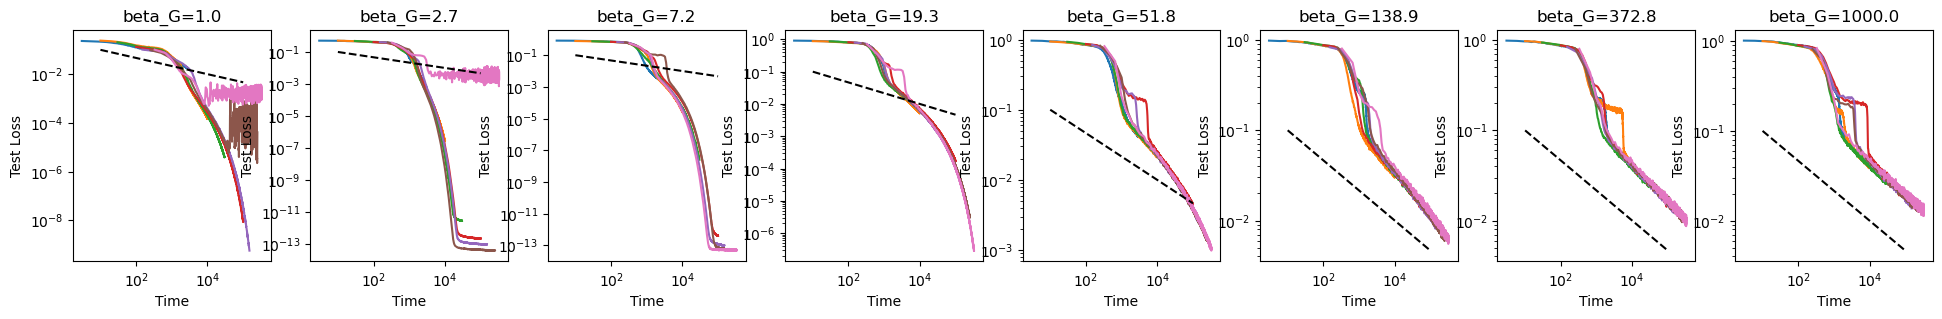

In [3]:
# 8 x 1 subplots
fig, axs = plt.subplots(1, 8, figsize=(24, 3), sharex=True)
for beta_G_id, beta_G in enumerate(beta_Gs):
    for lr_id, lr in enumerate(lrs[:-1]):
        axs[beta_G_id].plot(steps * lr, test_losses[lr_id, beta_G_id]) # lr_id = 4 is best
    axs[beta_G_id].plot([10, 1e+5], [.1, .1 / 1e+4 ** (1/3)], 'k--')
    axs[beta_G_id].set_title(f"beta_G={beta_G:.1f}")
    axs[beta_G_id].set_xlabel("Time")
    axs[beta_G_id].set_ylabel("Test Loss")
    axs[beta_G_id].set_xscale("log")
    axs[beta_G_id].set_yscale("log")

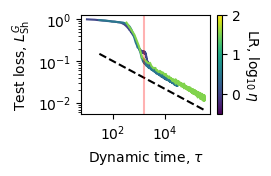

In [62]:
plt.figure(figsize=(2.6, 1.65), constrained_layout=True)
beta_G_id = -1
cmap = plt.get_cmap('viridis')
for lr_id in [1, 2, 6]:
    #lr = lrs[lr_id]
    log_lr = torch.tensor(lrs).log10()
    plt.plot(steps * lrs[lr_id], test_losses[lr_id, beta_G_id], color=cmap((log_lr[lr_id] - log_lr[0]) / (log_lr[-1] - log_lr[0])))
plt.plot([30, 3e+5], [.15, .15 / 1e+4 ** (1/3)], 'k--')
plt.axvline(x=1500, color='r', linestyle='-', alpha = 0.3)
plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"Dynamic time, $\tau$")
plt.ylabel(r"Test loss, $L_{\rm Sh}^{G}$")

# Create the colorbar
norm = mcolors.Normalize(vmin=torch.tensor(lrs).log10()[0], vmax=torch.tensor(lrs).log10()[-1])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
current_ax = plt.gca()  # Get the current axes
cbar = plt.colorbar(sm, ax=current_ax)
cbar.set_label(r'LR, $\log_{10} \eta$', rotation=270, labelpad=15)
plt.savefig("../../figures/Gloss.pdf")

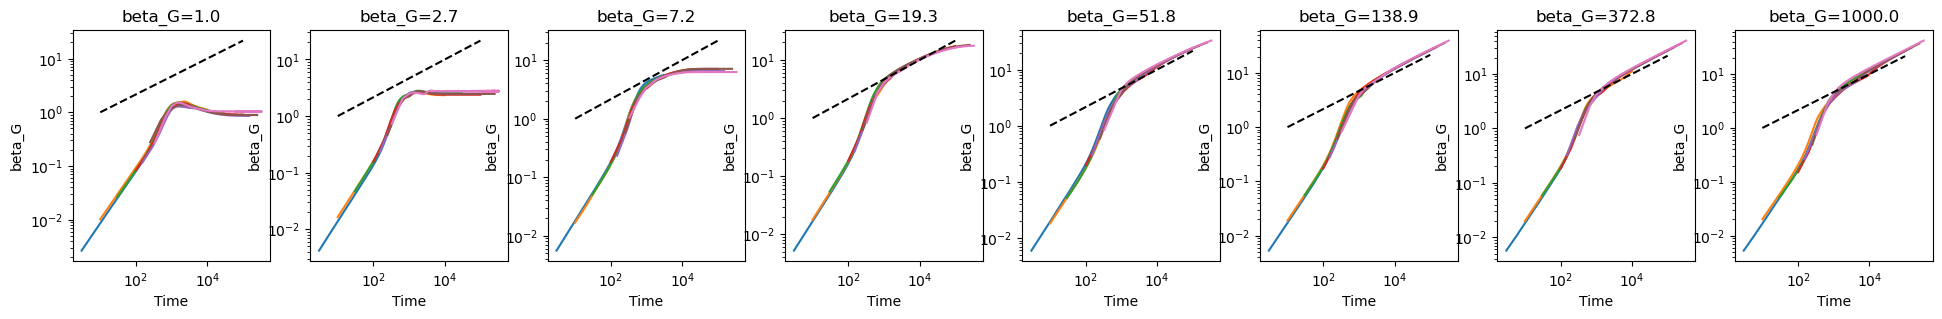

In [10]:
# 8 x 1 subplots
fig, axs = plt.subplots(1, 8, figsize=(24, 3), sharex=True)
for beta_G_id, beta_G in enumerate(beta_Gs):
    for lr_id, lr in enumerate(lrs[:-1]):
        axs[beta_G_id].plot(steps * lr, s_beta_G[lr_id, beta_G_id]) # lr_id = 4 is best
    axs[beta_G_id].plot([10, 1e+5], [1, 1e+4 ** (1/3)], 'k--')
    axs[beta_G_id].set_title(f"beta_G={beta_G:.1f}")
    axs[beta_G_id].set_xlabel("Time")
    axs[beta_G_id].set_ylabel("beta_G")
    axs[beta_G_id].set_xscale("log")
    axs[beta_G_id].set_yscale("log")

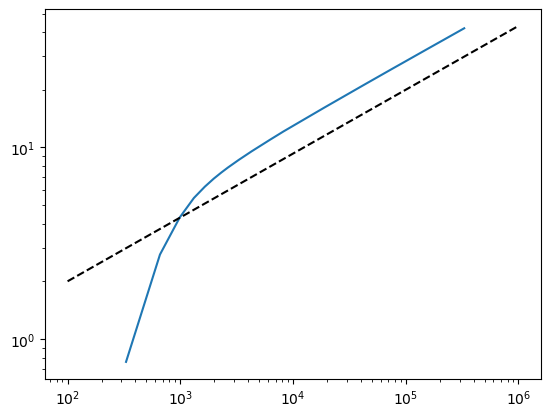

In [13]:
plt.plot(steps * lrs[-2], s_beta_G[-2, -1])
plt.plot([100, 1e+6], [2, 2* 1e+4 ** (1/3)], 'k--')
plt.xscale("log")
plt.yscale("log")

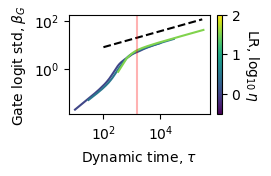

In [63]:
plt.figure(figsize=(2.6, 1.65), constrained_layout=True)
beta_G_id = -1
cmap = plt.get_cmap('viridis')
for lr_id in [1, 2, 6]:
    #lr = lrs[lr_id]
    log_lr = torch.tensor(lrs).log10()
    plt.plot(steps * lrs[lr_id], s_beta_G[lr_id, beta_G_id], color=cmap((log_lr[lr_id] - log_lr[0]) / (log_lr[-1] - log_lr[0])))
plt.plot([100, 3e+5], [8, 8 * 3e+3 ** (1/3)], 'k--')
plt.axvline(x=1500, color='r', linestyle='-', alpha = 0.3)
plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"Dynamic time, $\tau$")
plt.ylabel(r"Gate logit std, $\beta_G$")

# Create the colorbar
norm = mcolors.Normalize(vmin=torch.tensor(lrs).log10()[0], vmax=torch.tensor(lrs).log10()[-1])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
current_ax = plt.gca()  # Get the current axes
cbar = plt.colorbar(sm, ax=current_ax)
cbar.set_label(r'LR, $\log_{10} \eta$', rotation=270, labelpad=15)
plt.savefig("../../figures/Gbeta.pdf")

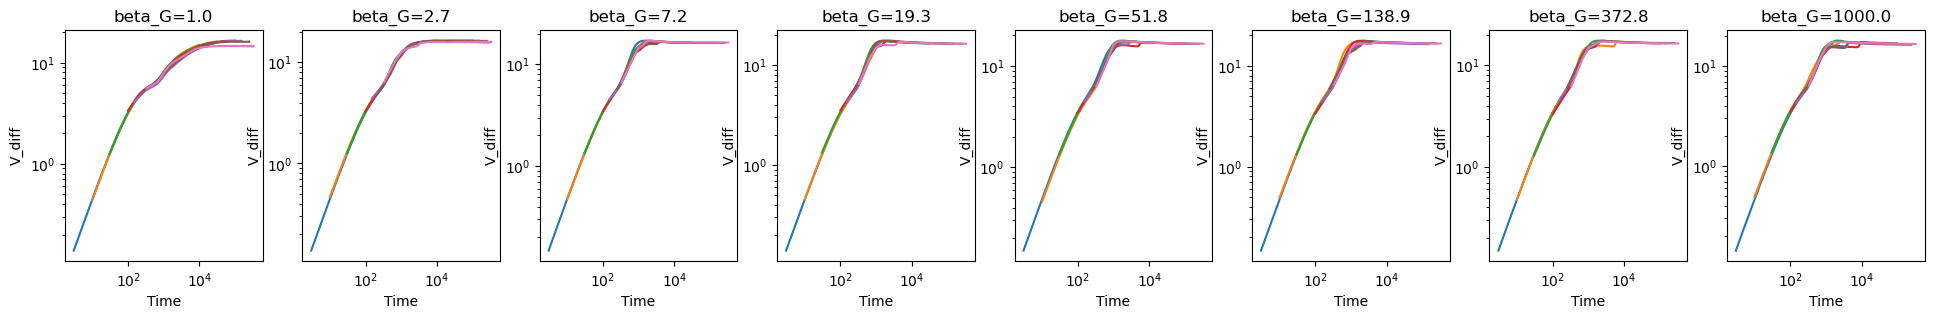

In [11]:
# 8 x 1 subplots
fig, axs = plt.subplots(1, 8, figsize=(24, 3), sharex=True)
for beta_G_id, beta_G in enumerate(beta_Gs):
    for lr_id, lr in enumerate(lrs[:-1]):
        axs[beta_G_id].plot(steps * lr, V_diff[lr_id, beta_G_id]) # lr_id = 4 is best
    axs[beta_G_id].set_title(f"beta_G={beta_G:.1f}")
    axs[beta_G_id].set_xlabel("Time")
    axs[beta_G_id].set_ylabel("V_diff")
    axs[beta_G_id].set_xscale("log")
    axs[beta_G_id].set_yscale("log")

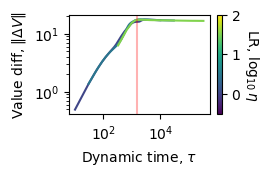

In [64]:
plt.figure(figsize=(2.6, 1.65), constrained_layout=True)
beta_G_id = -1
cmap = plt.get_cmap('viridis')
for lr_id in [1, 2, 6]:
    #lr = lrs[lr_id]
    log_lr = torch.tensor(lrs).log10()
    plt.plot(steps * lrs[lr_id], V_diff[lr_id, beta_G_id], color=cmap((log_lr[lr_id] - log_lr[0]) / (log_lr[-1] - log_lr[0])))
#plt.plot([100, 3e+5], [8, 8 * 3e+3 ** (1/3)], 'k--')
plt.axvline(x=1500, color='r', linestyle='-', alpha = 0.3)
plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"Dynamic time, $\tau$")
plt.ylabel(r"Value diff, $\| \Delta V \|$")

# Create the colorbar
norm = mcolors.Normalize(vmin=torch.tensor(lrs).log10()[0], vmax=torch.tensor(lrs).log10()[-1])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
current_ax = plt.gca()  # Get the current axes
cbar = plt.colorbar(sm, ax=current_ax)
cbar.set_label(r'LR, $\log_{10} \eta$', rotation=270, labelpad=15)
plt.savefig("../../figures/GVdiff.pdf")